## Nam Tu - 153076622 - Exercise 2

In [80]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# AN1 contains timestamps encoded as DDHHMMSS.
df1 = pd.read_csv("annotation1.AN1", skiprows=1, skipinitialspace=True)
df1.columns = df1.columns.str.strip()

time_text = df1["Time"].astype(str).str.strip().str.zfill(8)
df1["Time"] = time_text.str[2:4] + ":" + time_text.str[4:6] + ":" + time_text.str[6:8]
df1["Time seconds"] = pd.to_timedelta(df1["Time"]).dt.total_seconds()

df1.head()


,Time,VType,Variable,Value,Status,Unnamed: 5,Time seconds
0,10:00:58,CV,30001810,36.340000,8,NaN,36058.0
1,10:00:58,CV,30003500,222.500000,8,NaN,36058.0
2,10:01:03,MV,100,115.250000,16,NaN,36063.0
3,10:01:03,MV,110,61.610001,16,NaN,36063.0
4,10:01:03,MV,120,44.740002,16,NaN,36063.0


## 1. The number of annotations for the variables of interest differ greatly. The Peripheral Temperature (Tp) has almost 700 records, while Cardiac Index (CI) and Pulmonary capillary wedge pressure (PCWP) each has only around 25. This may be because peripheral temperature can be recorded continuously with a non-invasive probe on the skin, while the other 2 variables need to be recorded with a catheter that has to be threaded through the heart, making it much more difficult to record a large quantity at a time.

In [81]:
variable_counts = df1["Variable"].value_counts()
variable_counts.reindex([30001000, 400, 800], fill_value=0)


Variable
30001000     26
400         699
800          25
Name: count, dtype: int64

## 2. As mentioned by the exercise sheet, this model is simplified from the nuances that is present in the patient room, so the reliability of this model in terms of detecting the exact time of cardiac failure is to be taken with a grain of salt. However, the model is able to indicate a time frame of significant signs of cardiac failure (as seen in the plot by the large regions in red).

In [82]:
# Apply each rule to its own filtered dataframe.
ci_failure = df1[
    (df1["Variable"] == 30001000) & (df1["Value"] < 2.0)
].copy()
tp_failure = df1[
    (df1["Variable"] == 400) & (df1["Value"] < 32.5)
].copy()
other_failure = df1[
    (df1["Variable"] == 800) & (df1["Value"] < 10)
].copy()

ci_failure["Rule"] = "Cardiac index < 2.0"
tp_failure["Rule"] = "Tp < 32.5 C"
other_failure["Rule"] = "Variable 800 < 10"

# Keep every recording timestamp, then mark it True only when a rule matches.
rule_matches = pd.concat([ci_failure, tp_failure, other_failure], ignore_index=True)
matched_times = rule_matches[["Time", "Time seconds"]].drop_duplicates()
matched_times["Cardiac failure"] = True

all_times = df1[["Time", "Time seconds"]].drop_duplicates()
cardiac_failure_by_time = (
    all_times
    .merge(matched_times, on=["Time", "Time seconds"], how="left")
    .assign(**{"Cardiac failure": lambda data: data["Cardiac failure"].fillna(False)})
    .sort_values("Time seconds")
    .reset_index(drop=True)
)

rule_matches = rule_matches.sort_values(["Time seconds", "Variable"])
cardiac_failure_by_time


,Time,Time seconds,Cardiac failure
0,00:01:21,81.0,True
1,00:03:21,201.0,True
2,00:03:23,203.0,False
3,00:05:21,321.0,True
4,00:07:21,441.0,True
...,...,...,...
1073,23:53:23,86003.0,False
1074,23:55:21,86121.0,True
1075,23:57:21,86241.0,True
1076,23:58:23,86303.0,False


## 3. Code was written with the assistance of AI. The rule-based model, compared to the manual annotations, is able to capture severe and constant cases of cardiac failure but misses some cases where the intervals between signs of failures are longer. The rules are simplified and can only classify for discrete points in time instead of intervals, additionally the healthcare worker has access much more information to the patient than just sensor data such as visual cues. 

In [83]:
df2 = pd.read_csv(
    "annotation2.AN2",
    skiprows=1,
    skipinitialspace=True
)

df2.columns = df2.columns.str.strip()

time_text = df2["Time"].astype(str).str.strip().str.zfill(8)
df2["Time"] = time_text.str[2:4] + ":" + time_text.str[4:6] + ":" + time_text.str[6:8]

cardiac_variables = [
    15001114, 15001115, 15001116,
    15001117, 15001118, 15001119
]

# Keep the AN2 value codes in separate columns for each cardiac-failure variable.
manual_cardiac_values = (
    df2[df2["Variable"].isin(cardiac_variables)]
    .pivot_table(
        index="Time",
        columns="Variable",
        values="Value",
        aggfunc="last"
    )
    .reindex(columns=cardiac_variables)
    .reset_index()
)

# The supplied annotation table gives the interval boundaries.
# Value 1 = No, 2 = Yes, 3 = Can't be assessed.
manual_cardiac_intervals = pd.DataFrame([
    {"Start time": "10:00:00", "End time": "05:03:00", 15001116: 2},
    {"Start time": "11:54:00", "End time": "12:42:00", 15001114: 2},
    {"Start time": "12:37:00", "End time": "14:36:00", 15001115: 2},
    {"Start time": "19:41:00", "End time": "01:14:00", 15001116: 2},
], columns=["Start time", "End time"] + cardiac_variables)

# A midnight-crossing interval ends on the following day.
manual_cardiac_intervals["Start seconds"] = pd.to_timedelta(
    manual_cardiac_intervals["Start time"]
).dt.total_seconds()
manual_cardiac_intervals["End seconds"] = pd.to_timedelta(
    manual_cardiac_intervals["End time"]
).dt.total_seconds()
manual_cardiac_intervals.loc[
    manual_cardiac_intervals["End seconds"] <= manual_cardiac_intervals["Start seconds"],
    "End seconds"
] += 24 * 3600

# Manual cardiac-failure vector: True while any cardiac-failure variable is Yes.
manual_cardiac_intervals["Cardiac failure"] = (
    manual_cardiac_intervals[cardiac_variables].eq(2).any(axis=1)
)

manual_cardiac_intervals

,Start time,End time,15001114,15001115,15001116,15001117,15001118,15001119,Start seconds,End seconds,Cardiac failure
0,10:00:00,05:03:00,NaN,NaN,2.0,NaN,NaN,NaN,36000.0,104580.0,True
1,11:54:00,12:42:00,2.0,NaN,NaN,NaN,NaN,NaN,42840.0,45720.0,True
2,12:37:00,14:36:00,NaN,2.0,NaN,NaN,NaN,NaN,45420.0,52560.0,True
3,19:41:00,01:14:00,NaN,NaN,2.0,NaN,NaN,NaN,70860.0,90840.0,True


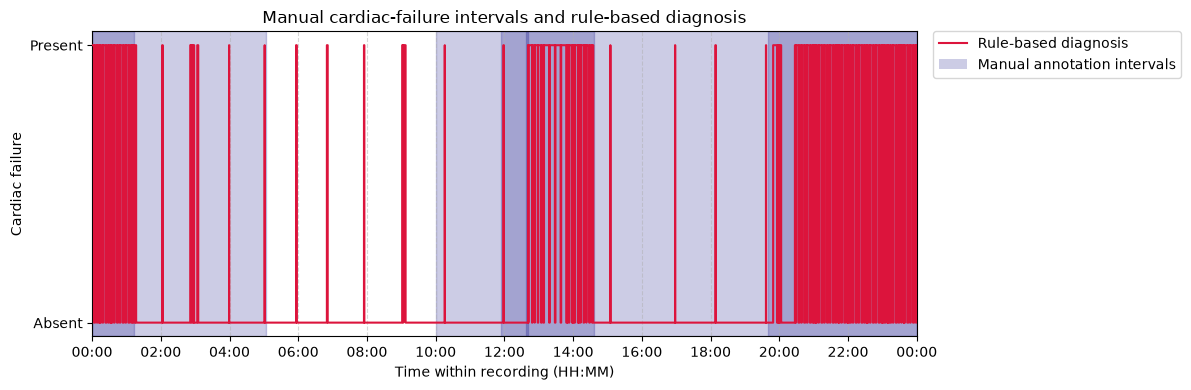

In [84]:
# Plot the rule-based diagnosis and manual cardiac-failure intervals together.
rule_data = cardiac_failure_by_time.sort_values("Time seconds").copy()
rule_data["Time datetime"] = pd.Timestamp("2000-01-01") + pd.to_timedelta(rule_data["Time seconds"], unit="s")

fig, ax = plt.subplots(figsize=(12, 4))
ax.step(
    rule_data["Time datetime"],
    rule_data["Cardiac failure"].astype(int),
    where="post",
    color="crimson",
    linewidth=1.5,
    label="Rule-based diagnosis",
    zorder=3,
)

# Reference intervals from the manual annotation table.
for _, interval in manual_cardiac_intervals.iterrows():
    start_seconds = interval["Start seconds"]
    end_seconds = interval["End seconds"]
    start_dt = pd.Timestamp("2000-01-01") + pd.to_timedelta(start_seconds, unit="s")
    end_dt = pd.Timestamp("2000-01-01") + pd.to_timedelta(end_seconds, unit="s")
    if end_seconds <= 24 * 3600:
        ax.axvspan(start_dt, end_dt, color="navy", alpha=0.20, zorder=1)
    else:
        ax.axvspan(start_dt, pd.Timestamp("2000-01-02"), color="navy", alpha=0.20, zorder=1)
        ax.axvspan(pd.Timestamp("2000-01-01"), end_dt - pd.Timedelta(days=1), color="navy", alpha=0.20, zorder=1)

from matplotlib.patches import Patch
from matplotlib.lines import Line2D
ax.legend(handles=[
    Line2D([0], [0], color="crimson", linewidth=1.5, label="Rule-based diagnosis"),
    Patch(facecolor="navy", alpha=0.20, label="Manual annotation intervals"),
], loc="upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0)
ax.set_yticks([0, 1], ["Absent", "Present"])
ax.set_ylabel("Cardiac failure")
ax.set_xlabel("Time within recording (HH:MM)")
ax.set_title("Manual cardiac-failure intervals and rule-based diagnosis")
ax.set_xlim(pd.Timestamp("2000-01-01"), pd.Timestamp("2000-01-02"))
ax.xaxis.set_major_locator(mdates.HourLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.grid(axis="x", linestyle="--", alpha=0.5)
fig.subplots_adjust(right=0.76)
fig.tight_layout()
plt.show()


## 4. Visually, the care activities understandably ramp up during cardiac failure, but also during early morning, perhaps due to many activities starting in the hospital in the morning in general (as seen from "Other CA annotation")

## Incorporating care activities time data with the patient diagnosis time data can help with prioritizing help between multiple patients. Patients that have cardiac failure but has been treated can be handed off to caretaking personnel, while those with cardiac failure that has yet been treated gets higher priority. This can help with the rule-based models, as they now can depend on previous actions as another variable instead of static numbers, meaning the models now work on trajectory-based information instead just raw instantaneous numbers.

In [85]:
care_activity_labels = {
    82: "Low CI and filling normal",
    83: "Low CI and filling high or normal (rcf)",
    84: "Low urine output (lcf)",
    85: "Low urine output (rcf)",
    86: "Low Tp, CI, filling normal or high (cf)",
    87: "Low Tp, CI, filling normal or high (rcf)",
    88: "CI normal or low, needs high FP (cf)",
    89: "CI normal or low, needs high FP (rcf)",
    90: "CI normal or low, FP high or normal, vasodil (cf)",
    91: "CI normal or low, FP high or normal, vasodil (rcf)",
    92: "CI normal or low, FP high or normal, inotrope (cf)",
    93: "CI normal or low, FP high or normal, inotrope (rcf)",
    116: "Left cardiac failure",
    117: "Right cardiac failure",
}

# Keep every care-activity annotation in AN2.
care_activities = df2[
    df2["VType"].astype(str).str.strip().eq("CA")
].copy()
care_activities["Activity"] = care_activities["Variable"].map(care_activity_labels)
care_activities["Activity"] = care_activities["Activity"].fillna(
    "CA code " + care_activities["Variable"].astype(str)
)
care_activities["Time seconds"] = pd.to_timedelta(
    care_activities["Time"]
).dt.total_seconds()

# Determine whether each care activity occurs inside a manual cardiac-failure interval.
def in_manual_interval(time_seconds):
    for _, interval in manual_cardiac_intervals.iterrows():
        start = interval["Start seconds"] % (24 * 3600)
        end = interval["End seconds"]
        if end <= 24 * 3600:
            if start <= time_seconds <= end:
                return True
        else:
            if time_seconds >= start or time_seconds <= end - 24 * 3600:
                return True
    return False

care_activities["During manual cardiac failure"] = care_activities["Time seconds"].map(
    in_manual_interval
)

care_activity_summary = (
    care_activities
    .groupby(["Variable", "Activity", "During manual cardiac failure"])
    .size()
    .rename("Count")
    .reset_index()
)


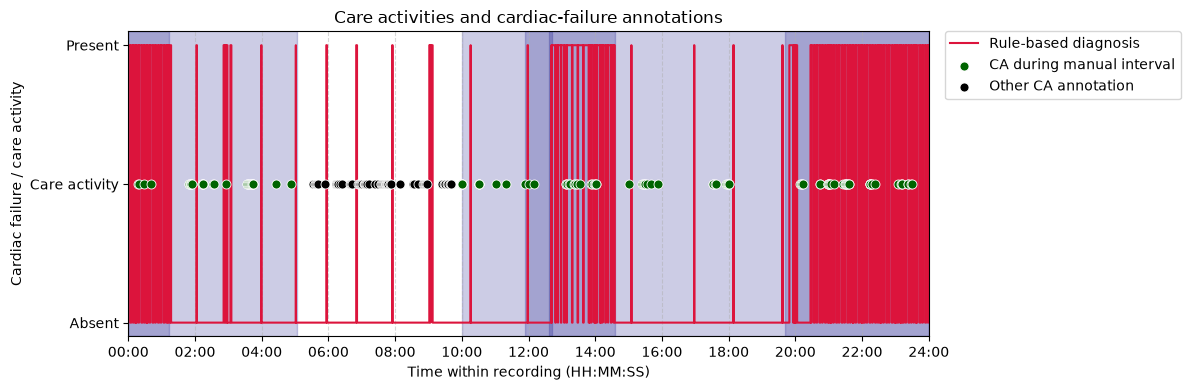

In [86]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.step(
    rule_data["Time seconds"] / 3600,
    rule_data["Cardiac failure"].astype(int),
    where="post", color="crimson", linewidth=1.5,
    label="Rule-based diagnosis"
)

for _, interval in manual_cardiac_intervals.iterrows():
    start = interval["Start seconds"] / 3600
    end = interval["End seconds"] / 3600
    if end <= 24:
        ax.axvspan(start, end, color="navy", alpha=0.20)
    else:
        ax.axvspan(start, 24, color="navy", alpha=0.20)
        ax.axvspan(0, end - 24, color="navy", alpha=0.20)

inside = care_activities[care_activities["During manual cardiac failure"]]
outside = care_activities[~care_activities["During manual cardiac failure"]]
ax.scatter(
    inside["Time seconds"] / 3600,
    [0.5] * len(inside),
    color="darkgreen", s=42, alpha=1.0,
    edgecolors="white", linewidths=0.6,
    zorder=10, label="CA during manual interval"
)
ax.scatter(
    outside["Time seconds"] / 3600,
    [0.5] * len(outside),
    color="black", s=42, alpha=1.0,
    edgecolors="white", linewidths=0.6,
    zorder=10, label="Other CA annotation"
)

from matplotlib.patches import Patch
from matplotlib.lines import Line2D
handles, labels = ax.get_legend_handles_labels()
ax.set_yticks([0, 0.5, 1], ["Absent", "Care activity", "Present"])
ax.set_xlabel("Time within recording (HH:MM:SS)")
ax.set_ylabel("Cardiac failure / care activity")
ax.set_title("Care activities and cardiac-failure annotations")
ax.set_xlim(0, 24)
ax.set_xticks(range(0, 25, 2), [f"{hour:02d}:00" for hour in range(0, 25, 2)])
ax.grid(axis="x", linestyle="--", alpha=0.5)
fig.subplots_adjust(right=0.76)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0)
fig.tight_layout()
plt.show()
